# JDsearch – Model comparison: does shopper history improve the ranking?

**Business question.** Does a shopper's own history improve the ranking of the pre-retrieved candidates compared with a ranking that uses only the query and the product? And for which shoppers is the gain largest?

| Model | Features | Role |
|---|---|---|
| **A**, non-personalized, f(Q, P) | 7 query–product features | baseline |
| **B**, personalized, f(Q, P, H_u) | the same 7 + 23 history features | tested model |

Both are LightGBM lambdarank models trained with the same settings, the same candidates and the same labels, so the history block is the only difference. The primary metric is NDCG@10 (linear gains 0 to 3), with MRR and Hit@10 as complementary metrics. A is reference-checked against random ranking and popularity only.

**Contents**

| Section | What happens |
|---|---|
| 0 | Setup |
| 1 | Load both models and check that the comparison is controlled |
| 2 | Load the evaluation data and score both models |
| 3 | Main answer: Δ metrics with bootstrap intervals |
| 4 | Who gains: history amount, recency, click window, list size, seen vs unseen |
| 5 | What drives the gain: feature importance and group ablations |

**Evaluation split.** Both models were trained on all usable training users, with validation used for early stopping. This notebook evaluates the saved models on the test split (`SPLIT = 'test'`). Setting `SPLIT = 'val'` instead reproduces the validation evaluation.

## 0. Setup
`MODEL_A_DIR` and `MODEL_B_DIR` are the folders written by the two training notebooks (model file, `run_config.json`, evaluator). `SPLIT` is the data the comparison runs on: `'val'` during development, `'test'` for the final numbers.

In [ ]:
import importlib.util, subprocess, sys
missing = [n for n in ['lightgbm', 'pyarrow', 'scikit-learn'] if importlib.util.find_spec({'scikit-learn': 'sklearn'}.get(n, n)) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import os, json, shutil, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import lightgbm as lgb
try: from IPython.display import display
except ImportError: display = print

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/bt4222_project')
    LOCAL = Path('/content/jd_local/ModelComparison')
except ImportError:
    BASE = Path(os.environ['JD_BASE'])
    LOCAL = Path(os.environ['JD_LOCAL']) / 'model_comparison'
LOCAL.mkdir(parents=True, exist_ok=True)

FEATURE_DIR = BASE / 'Data/Features'
MODEL_A_DIR = BASE / 'Data/Models/Baseline'      # final run: Data/Models/BaselineFull
MODEL_B_DIR = BASE / 'Data/Models/Advanced'      # final run: the folder of the full-data Model B
SPLIT = 'test'                                    # 'val' while developing; 'test' once, for the final numbers
SEED, K = 42, 10
KEYS = ['user_id', 'wid']
print('Model A:', MODEL_A_DIR, '\nModel B:', MODEL_B_DIR, '\nEvaluating on:', SPLIT)

Mounted at /content/drive
Model A: /content/drive/MyDrive/bt4222_project/Data/Models/Baseline 
Model B: /content/drive/MyDrive/bt4222_project/Data/Models/Advanced 
Evaluating on: test


## 1. Load both models and check that the comparison is controlled
Loads each saved model and its `run_config.json`. A difference in anything other than the history features would make the gap between A and B uninterpretable, so the cell stops if any of these differ:

- the model's feature names equal the features recorded in its config; Model B's baseline block equals Model A's feature list, with the 23 history features added;
- the LightGBM parameters, the seed and the evaluator code;
- the training and validation candidates and labels (data fingerprints) and the numbers of training rows and queries.

In [ ]:
def load_run(folder, model_file):
    for name in (model_file, 'run_config.json', 'ranking_evaluation.py'):
        if not (folder / name).is_file():
            raise FileNotFoundError(f'{folder / name} missing: rerun the save cell of that training notebook')
    cfg = json.loads((folder / 'run_config.json').read_text())
    return cfg, lgb.Booster(model_file=str(folder / model_file))

cfg_A, model_A = load_run(MODEL_A_DIR, 'model_A.txt')
cfg_B, model_B = load_run(MODEL_B_DIR, 'model_B.txt')
FEATURES_A, FEATURES_B = model_A.feature_name(), model_B.feature_name()

assert FEATURES_A == cfg_A['features'], 'Model A: model features differ from its config'
assert FEATURES_B == cfg_B['features'], 'Model B: model features differ from its config'
assert FEATURES_B[:len(FEATURES_A)] == FEATURES_A and cfg_B['features_baseline'] == FEATURES_A, 'Model B must start with exactly Model A\'s features'
HISTORY = FEATURES_B[len(FEATURES_A):]
problems = []
diff = {k for k in set(cfg_A['parameters']) | set(cfg_B['parameters']) if cfg_A['parameters'].get(k) != cfg_B['parameters'].get(k)}
if diff: problems.append(f'LightGBM parameters differ: {sorted(diff)}')
if cfg_A['seed'] != cfg_B['seed']: problems.append('seeds differ')
if (MODEL_A_DIR / 'ranking_evaluation.py').read_text() != (MODEL_B_DIR / 'ranking_evaluation.py').read_text(): problems.append('evaluator code differs')
for k in ('train_keys_labels', 'val_keys_labels'):
    if cfg_A['fingerprints'][k] != cfg_B['fingerprints'][k]: problems.append(f'{k}: the two models saw different candidates or labels')
if cfg_A['rows'] != cfg_B['rows'] or cfg_A['queries'] != cfg_B['queries']: problems.append('row or query counts differ')
if problems: raise ValueError('The comparison is not controlled:\n - ' + '\n - '.join(problems))

summary = pd.DataFrame({
    'Model A': dict(stage=cfg_A['stage'], features=len(FEATURES_A), best_iteration=cfg_A['best_iteration'],
                    train_queries=cfg_A['queries']['train'], train_rows=cfg_A['rows']['train'], val_queries=cfg_A['queries']['val']),
    'Model B': dict(stage=cfg_B['stage'], features=len(FEATURES_B), best_iteration=cfg_B['best_iteration'],
                    train_queries=cfg_B['queries']['train'], train_rows=cfg_B['rows']['train'], val_queries=cfg_B['queries']['val']),
})
display(summary)
p = cfg_A['parameters']
print(f"identical settings: objective {p['objective']}, learning rate {p['learning_rate']}, leaves {p['num_leaves']}, min child samples {p['min_child_samples']}, "
      f"colsample {p['colsample_bytree']}, subsample {p['subsample']}, seed {cfg_A['seed']}")
print(f'Model B adds {len(HISTORY)} history features to the {len(FEATURES_A)} of Model A: OK')

,Model A,Model B
stage,development_validation,full_validation
features,7,30
best_iteration,186,479
train_queries,120174,120174
train_rows,10750112,10750112
val_queries,25787,25787


identical settings: objective lambdarank, learning rate 0.05, leaves 63, min child samples 100, colsample 0.8, subsample 0.8, seed 42
Model B adds 23 history features to the 7 of Model A: OK


Summary (model check). Both models are trained with identical LightGBM settings, the same seed and the same 120,174 training queries (10,750,112 candidate rows). The same 25,787 validation queries are used for early stopping. Final evaluation uses 25,767 test queries. Model A uses 7 query–product, popularity and metadata features; Model B adds 23 history features. Early stopping selects 186 trees for A and 479 for B. The "stage" label of Model A still says development, but the model was trained on all usable training users.

## 2. Load the evaluation data and score both models
Reads the Model A features, the history features and the labels of `SPLIT` and joins them by (user_id, wid), as in the training notebooks. Candidates are shuffled within each query with a seed; the evaluator breaks ties with a random priority that depends only on the keys. Queries without a positive are excluded, as in training.

For `val`, the data fingerprints must equal those stored by the two training runs; this proves that the comparison uses exactly the candidates, labels and features the models were developed on. For `test` there is nothing to compare with, so the checks are the key and label checks only.

In [ ]:
def fingerprint(frame):
    ordered = frame.sort_values(KEYS).reset_index(drop=True)
    return hashlib.sha256(pd.util.hash_pandas_object(ordered, index=False).to_numpy().tobytes()).hexdigest()

def local_input(name):
    src = FEATURE_DIR / f'{name}.parquet'
    if not src.is_file(): raise FileNotFoundError(f'{src} missing. Check the Drive sync of the feature files.')
    dst = LOCAL / src.name
    shutil.copy2(src, dst)
    return dst

def load_eval(tag):
    fa = pd.read_parquet(local_input(f'featA_{tag}'))[KEYS + FEATURES_A]
    fb = pd.read_parquet(local_input(f'featB_hist_{tag}'))[KEYS + HISTORY]
    b = pd.read_parquet(local_input(f'base_{tag}'), columns=KEYS + ['label'])
    d = b.merge(fa, on=KEYS, how='outer', validate='one_to_one', indicator='_a')
    d = d.merge(fb, on=KEYS, how='outer', validate='one_to_one', indicator='_b')
    if not (d._a.eq('both').all() and d._b.eq('both').all()): raise ValueError(f'{tag}: labels and features contain different candidates')
    d = d.drop(columns=['_a', '_b'])
    if d[KEYS].isna().any().any() or not d.label.isin([0, 1, 2, 3]).all(): raise ValueError(f'{tag}: invalid keys or labels')
    d = d.loc[d.groupby('user_id').label.transform('max').gt(0)].sort_values(KEYS).reset_index(drop=True)
    d['_s'] = np.random.default_rng(SEED).random(len(d))
    d = d.sort_values(['user_id', '_s']).drop(columns='_s').reset_index(drop=True)
    d[FEATURES_B] = d[FEATURES_B].astype('float32')
    print(f'{tag}: {len(d):,} candidate rows, {d.user_id.nunique():,} queries')
    return d

data = load_eval(SPLIT)
if SPLIT == 'val':
    assert fingerprint(data[KEYS + ['label']]) == cfg_A['fingerprints']['val_keys_labels'], 'validation candidates or labels differ from the training runs'
    assert fingerprint(data[KEYS + FEATURES_A]) == cfg_A['fingerprints']['val_features'], 'Model A features differ from the ones Model A was trained with'
    assert fingerprint(data[KEYS + FEATURES_B]) == cfg_B['fingerprints']['val_features'], 'Model B features differ from the ones Model B was trained with'
    print('data fingerprints equal those of both training runs: OK')

exec((MODEL_A_DIR / 'ranking_evaluation.py').read_text())          # the evaluator both models were developed with
evaluate = make_evaluator(data[KEYS], data.label.to_numpy(), k=K, seed=SEED)

scores = {'Model A': model_A.predict(data[FEATURES_A]), 'Model B': model_B.predict(data[FEATURES_B])}
scores['Random'] = np.random.default_rng(SEED + 1).random(len(data))
scores['Popularity only'] = np.rint(np.expm1(data[['prod_pop_ord', 'prod_pop_cart', 'prod_pop_click']].to_numpy(dtype=np.float64))).sum(axis=1)
results = pd.DataFrame({name: evaluate(scores[name]) for name in ['Random', 'Popularity only', 'Model A', 'Model B']}).T
results.index.name = 'ranking'
display(results)

if SPLIT == 'val':          # the saved models must reproduce the metrics stored at training time
    for name, cfg in (('Model A', cfg_A), ('Model B', cfg_B)):
        if 'metrics' in cfg: saved = cfg['metrics'][name]
        else: saved = {'ndcg10': cfg['early_stopping']['best_validation_ndcg10']}
        gap = max(abs(results.loc[name, m] - saved[m]) for m in saved if m in ('ndcg10', 'mrr', 'hit10'))
        print(f'{name}: largest difference to the metrics stored at training time = {gap:.2e}')
        assert gap < 1e-6, f'{name} does not reproduce its stored validation metrics: the saved model or the data changed'
print(f'NDCG@10 B minus A on {SPLIT}: {results.loc["Model B", "ndcg10"] - results.loc["Model A", "ndcg10"]:+.4f}')

test: 2,304,086 candidate rows, 25,767 queries


,ndcg10,mrr,hit10
ranking,,,
Random,0.085233,0.102208,0.229906
Popularity only,0.340049,0.336682,0.639423
Model A,0.352640,0.350301,0.654054
Model B,0.405954,0.411242,0.704622


NDCG@10 B minus A on test: +0.0533


## 3. Main answer: does history improve the ranking?
Each query is scored by Model A and by Model B, so the comparison is **paired**: the unit is the per-query difference B − A. The 95% intervals come from a paired bootstrap over queries (1,000 resamples, seed 42). An interval that excludes 0 provides evidence of a nonzero average difference under query-level resampling. It does not account for variation from retraining the models or potential systematic biases in the data.

The cell reports ΔNDCG@10 (primary), ΔMRR and ΔHit@10 (complementary), the share of queries where B ranks better, equal or worse, and the two reference rankings (random and popularity only) to show where A and B sit.

,random,popularity,model_A,model_B,delta,ci_low,ci_high,relative_gain_pct
metric,,,,,,,,
NDCG@10,0.085233,0.340049,0.352640,0.405954,0.053314,0.050481,0.056059,15.1%
MRR,0.102208,0.336682,0.350301,0.411242,0.060941,0.057332,0.064323,17.4%
Hit@10,0.229906,0.639423,0.654054,0.704622,0.050569,0.046687,0.054489,7.7%


B ranks better in 28.6% of queries, identical in 52.6%, worse in 18.8% (NDCG@10)
ΔNDCG@10 = +0.0533  [95% CI +0.0505, +0.0561]  ->  B is better than A beyond sampling noise


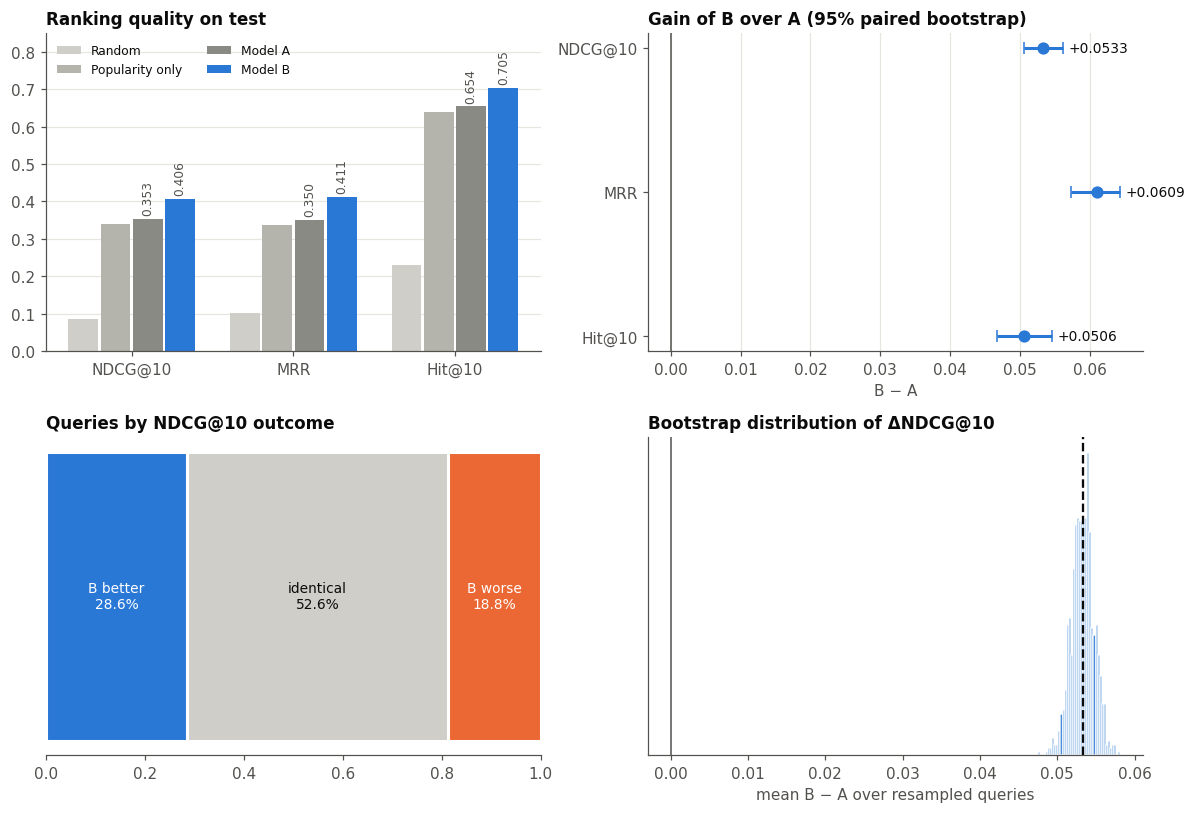

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

OUT_DIR = BASE / 'Data/Results/ModelComparison' / SPLIT
OUT_DIR.mkdir(parents=True, exist_ok=True)
N_BOOT = 1000
MIN_N = 200                       # smaller groups are shown greyed out / skipped in heatmaps

C = dict(A='#8a8a85', B='#2a78d6', ref='#cfcec8', up='#2a78d6', down='#eb6834', ink='#0b0b0b', mute='#52514e', grid='#e6e5e0')
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
                     'axes.edgecolor': C['mute'], 'axes.labelcolor': C['mute'], 'xtick.color': C['mute'], 'ytick.color': C['mute'],
                     'text.color': C['ink'], 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10, 'figure.dpi': 110})

def clean(ax, axis='x'):
    ax.grid(axis=axis, color=C['grid'], lw=0.8); ax.set_axisbelow(True)

def save_show(fig, name):
    fig.tight_layout(); fig.savefig(OUT_DIR / f'{name}.png', dpi=160, bbox_inches='tight'); plt.show()

def paired_boot(diff, n_boot=N_BOOT, seed=SEED):
    """Mean of a per-query difference with a 95% percentile interval over query resamples."""
    diff = np.asarray(diff, dtype=float); n = len(diff)
    if n < 2: return diff.mean() if n else np.nan, np.nan, np.nan, np.array([])
    rng = np.random.default_rng(seed); means = np.empty(n_boot)
    for s in range(0, n_boot, 100):
        e = min(n_boot, s + 100)
        means[s:e] = diff[rng.integers(0, n, (e - s, n))].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return diff.mean(), lo, hi, means

# per-query metrics of every ranking, aligned on user_id
pq = {name: evaluate(scores[name], per_query=True).set_index('user_id') for name in ['Random', 'Popularity only', 'Model A', 'Model B']}
assert pq['Model A'].index.equals(pq['Model B'].index)

METRICS = {'ndcg10': 'NDCG@10', 'mrr': 'MRR', 'hit10': 'Hit@10'}
rows, boots = [], {}
for m, label in METRICS.items():
    d = pq['Model B'][m] - pq['Model A'][m]
    mean, lo, hi, boots[m] = paired_boot(d)
    rows.append(dict(metric=label, random=pq['Random'][m].mean(), popularity=pq['Popularity only'][m].mean(),
                     model_A=pq['Model A'][m].mean(), model_B=pq['Model B'][m].mean(), delta=mean, ci_low=lo, ci_high=hi,
                     relative_gain_pct=100 * mean / pq['Model A'][m].mean()))
main = pd.DataFrame(rows).set_index('metric')
display(main.style.format('{:.4f}').format({'relative_gain_pct': '{:.1f}%'}))

dq = (pq['Model B'].ndcg10 - pq['Model A'].ndcg10).to_numpy()
tol = 1e-12
share = dict(better=(dq > tol).mean(), equal=(np.abs(dq) <= tol).mean(), worse=(dq < -tol).mean())
print(f"B ranks better in {share['better']:.1%} of queries, identical in {share['equal']:.1%}, worse in {share['worse']:.1%} (NDCG@10)")
d_ndcg = main.loc['NDCG@10']
print(f"ΔNDCG@10 = {d_ndcg.delta:+.4f}  [95% CI {d_ndcg.ci_low:+.4f}, {d_ndcg.ci_high:+.4f}]  ->  "
      + ('B is better than A beyond sampling noise' if d_ndcg.ci_low > 0 else 'the interval includes 0: no reliable difference' if d_ndcg.ci_high > 0 else 'B is worse than A'))

fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
# (a) levels
a = ax[0, 0]; x = np.arange(3); w = 0.2
for i, (name, col) in enumerate([('Random', C['ref']), ('Popularity only', '#b4b3ac'), ('Model A', C['A']), ('Model B', C['B'])]):
    vals = [pq[name][m].mean() for m in METRICS]
    a.bar(x + (i - 1.5) * w, vals, w * 0.92, color=col, label=name)
    if name in ('Model A', 'Model B'):
        for xi, v in zip(x + (i - 1.5) * w, vals): a.text(xi, v + 0.01, f'{v:.3f}', ha='center', va='bottom', rotation=90, fontsize=8, color=C['mute'])
a.set_xticks(x); a.set_xticklabels(list(METRICS.values())); a.set_ylim(0, 0.85); a.set_title('Ranking quality on ' + SPLIT); clean(a, 'y'); a.legend(frameon=False, fontsize=8, ncol=2)
# (b) deltas
b = ax[0, 1]
for i, (m, label) in enumerate(METRICS.items()):
    r = main.loc[label]
    b.errorbar(r.delta, i, xerr=[[r.delta - r.ci_low], [r.ci_high - r.delta]], fmt='o', color=C['B'], ms=7, capsize=4, lw=2)
    b.text(r.ci_high + 0.0008, i, f'{r.delta:+.4f}', va='center', fontsize=9)
b.axvline(0, color=C['mute'], lw=1); b.set_yticks(range(3)); b.set_yticklabels(list(METRICS.values())); b.invert_yaxis()
b.set_title('Gain of B over A (95% paired bootstrap)'); b.set_xlabel('B − A'); clean(b)
# (c) win / tie / lose
c = ax[1, 0]; left = 0
for key, col, lab in (('better', C['up'], 'B better'), ('equal', C['ref'], 'identical'), ('worse', C['down'], 'B worse')):
    c.barh(0, share[key], left=left, color=col, height=0.5, edgecolor='white', lw=2)
    if share[key] > 0.08: c.text(left + share[key] / 2, 0, f'{lab}\n{share[key]:.1%}', ha='center', va='center', fontsize=9, color='white' if key != 'equal' else C['ink'])
    left += share[key]
c.set_xlim(0, 1); c.set_yticks([]); c.set_title('Queries by NDCG@10 outcome'); c.spines['left'].set_visible(False)
# (d) bootstrap distribution
d = ax[1, 1]
d.hist(boots['ndcg10'], bins=40, color=C['B'], alpha=0.85, edgecolor='white')
d.axvline(0, color=C['mute'], lw=1); d.axvline(d_ndcg.delta, color=C['ink'], lw=1.5, ls='--')
d.set_title('Bootstrap distribution of ΔNDCG@10'); d.set_xlabel('mean B − A over resampled queries'); d.set_yticks([])
save_show(fig, '3_main_result')
main.to_csv(OUT_DIR / 'main_result.csv')

## 4. Who gains? Gain by shopper and query characteristics
The same paired difference (B − A, NDCG@10) is computed inside groups of queries. The characteristics come from `tests_<split>` (history amount, time since the last event, number of clicks in the 7-day click window, candidate-list size) and from the candidates themselves (was a relevant product already in the history?). Every group shows its number of queries and a 95% paired bootstrap interval.

Read these as descriptive: the characteristics are correlated (long histories are also recent), so the regression at the end of the section estimates each factor while holding the others fixed.

queries with a relevant product already in the history: 14.9%; share of all relevant candidates that were seen before: 9.2%


dimension,group,n,ndcg_A,ndcg_B,delta,ci_low,ci_high,rel_gain_pct
History amount (events),1–22,5272,0.3549,0.3964,+0.0415,+0.0363,+0.0471,+11.7%
History amount (events),23–54,5070,0.3526,0.4028,+0.0502,+0.0443,+0.0574,+14.2%
History amount (events),55–111,5181,0.3515,0.4081,+0.0566,+0.0505,+0.0631,+16.1%
History amount (events),112–230,5101,0.3497,0.4061,+0.0564,+0.0493,+0.0628,+16.1%
History amount (events),231–3817,5143,0.3544,0.4165,+0.0622,+0.0556,+0.0676,+17.5%
Time since last event,≤1 day,16381,0.3442,0.4193,+0.0751,+0.0712,+0.0789,+21.8%
Time since last event,1–7 days,6324,0.3659,0.3840,+0.0181,+0.0140,+0.0222,+4.9%
Time since last event,7–30 days,1919,0.3784,0.3925,+0.0141,+0.0075,+0.0224,+3.7%
Time since last event,30–90 days,869,0.3615,0.3652,+0.0037,-0.0053,+0.0116,+1.0%
Time since last event,90–365 days,274,0.3441,0.3412,-0.0028,-0.0143,+0.0086,-0.8%


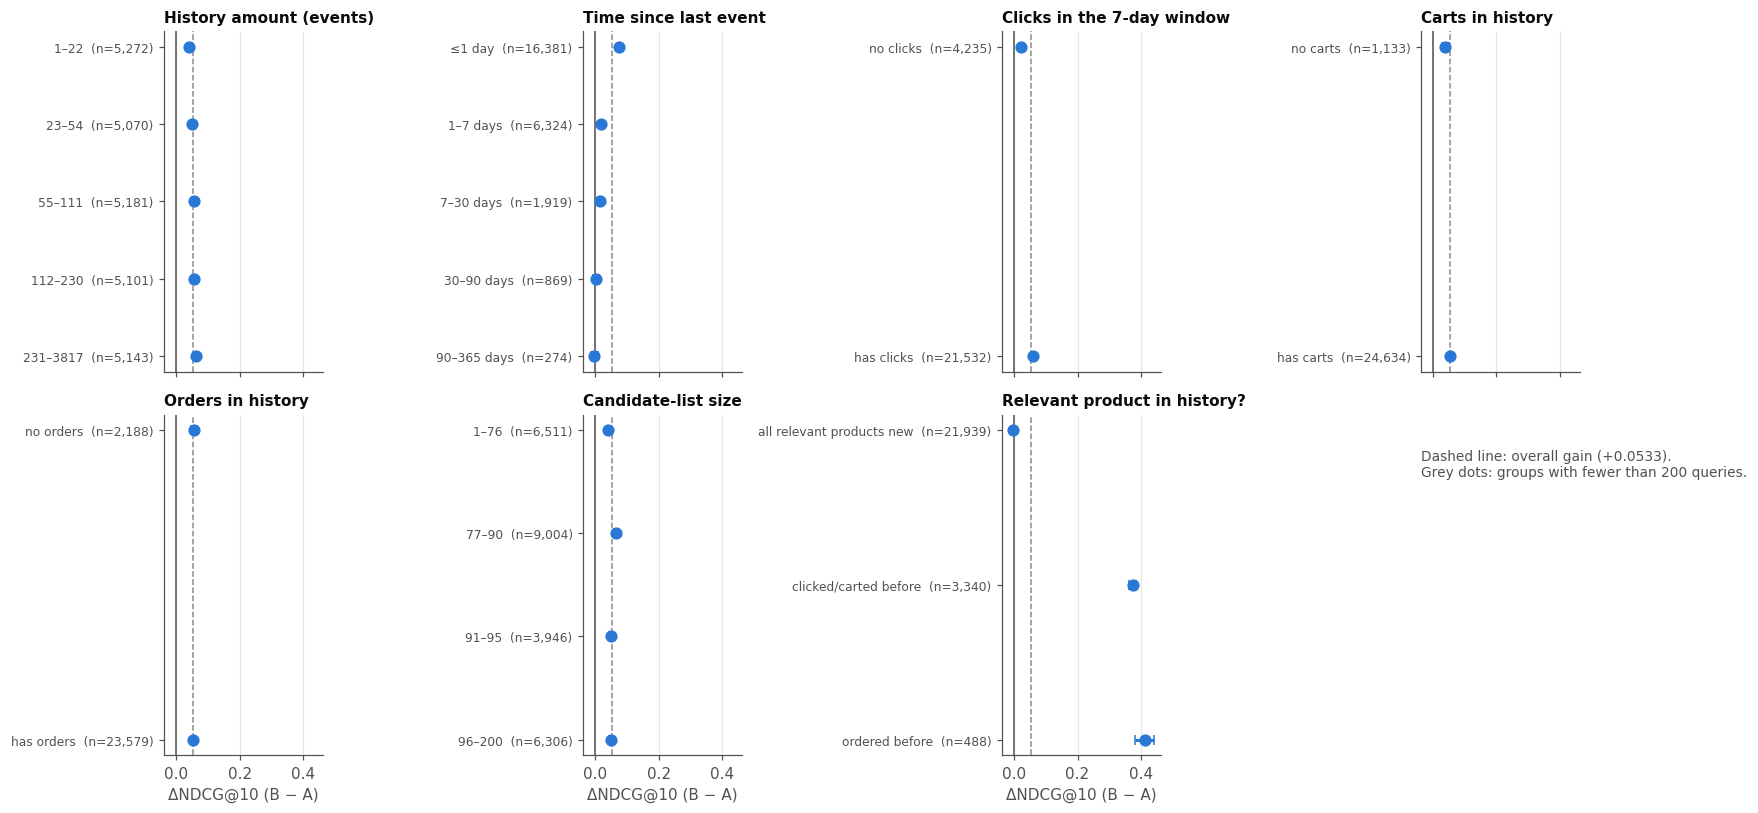

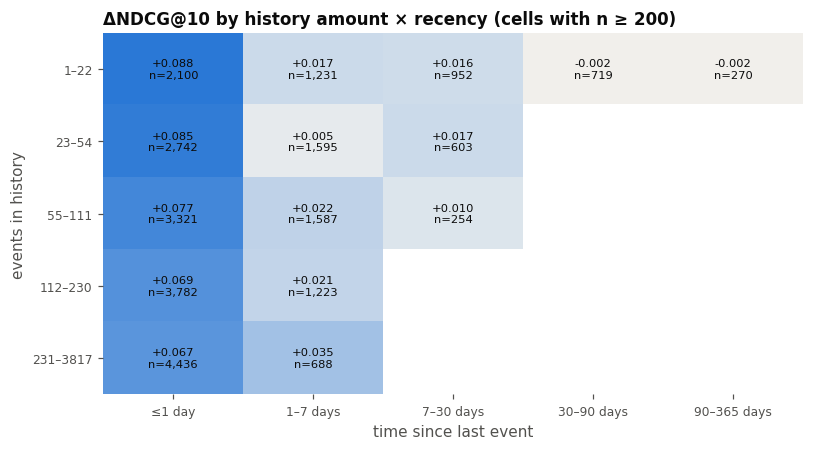

,coef,ci_low,ci_high,p
log history size,-0.0087,-0.0113,-0.0060,1.17e-10
log days since last event,-0.0010,-0.0040,+0.0021,0.529
has clicks (7-day window),+0.0048,+0.0018,+0.0078,0.00153
log candidates,+0.0051,+0.0029,+0.0072,3.58e-06
relevant product seen before,+0.1360,+0.1321,+0.1400,0


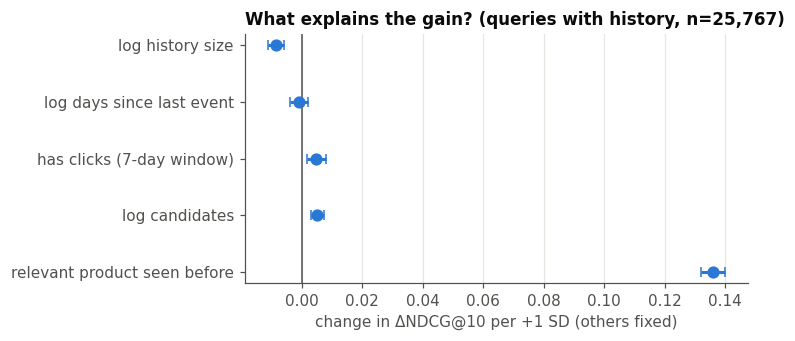

In [ ]:
src = BASE / 'Data/Processed' / f'tests_{SPLIT}.parquet'
if not src.is_file(): raise FileNotFoundError(f'{src} missing')
tests = pd.read_parquet(src)
assert tests.user_id.is_unique, 'tests table must have one row per query'
keep = ['n_cand', 'n_hist', 'last_gap_s', 'n_click', 'n_cart', 'n_ord']
Q = pd.DataFrame({'ndcgA': pq['Model A'].ndcg10, 'ndcgB': pq['Model B'].ndcg10,
                  'mrrA': pq['Model A'].mrr, 'mrrB': pq['Model B'].mrr, 'hitA': pq['Model A'].hit10, 'hitB': pq['Model B'].hit10})
Q['dNDCG'] = Q.ndcgB - Q.ndcgA
Q = Q.join(tests.set_index('user_id')[keep], how='left')
assert Q[['n_cand', 'n_hist']].notna().all().all(), 'some evaluated queries are missing in the tests table'

# seen vs unseen: was a relevant candidate already in the shopper's history (same product, any event type)?
prev_any = data[['prev_n_ord', 'prev_n_cart', 'prev_n_click']].fillna(0).to_numpy().sum(axis=1) > 0
prev_ord = data.prev_n_ord.fillna(0).to_numpy() > 0
is_pos = data.label.to_numpy() > 0
seen = pd.DataFrame({'user_id': data.user_id.to_numpy(), 'n_pos': is_pos, 'n_pos_seen': is_pos & prev_any, 'n_pos_ord': is_pos & prev_ord}).groupby('user_id').sum()
Q = Q.join(seen)
print(f"queries with a relevant product already in the history: {(Q.n_pos_seen > 0).mean():.1%}; "
      f"share of all relevant candidates that were seen before: {Q.n_pos_seen.sum() / Q.n_pos.sum():.1%}")

def qbins(s, q):
    edges = np.unique(s.quantile(np.linspace(0, 1, q + 1)).round().astype(int))
    labels = [f'{edges[i] + (1 if i else 0)}–{edges[i + 1]}' for i in range(len(edges) - 1)]
    return pd.cut(s, bins=edges, labels=labels, include_lowest=True, ordered=True)

days = Q.last_gap_s / 86400
dims = {
    'History amount (events)': qbins(Q.n_hist, 5),
    'Time since last event': pd.cut(days, [-np.inf, 1, 7, 30, 90, 365, np.inf], labels=['≤1 day', '1–7 days', '7–30 days', '30–90 days', '90–365 days', '>1 year']).cat.add_categories('no history').fillna('no history'),
    'Clicks in the 7-day window': pd.Series(np.where(Q.n_click > 0, 'has clicks', 'no clicks'), index=Q.index),
    'Carts in history': pd.Series(np.where(Q.n_cart > 0, 'has carts', 'no carts'), index=Q.index),
    'Orders in history': pd.Series(np.where(Q.n_ord > 0, 'has orders', 'no orders'), index=Q.index),
    'Candidate-list size': qbins(Q.n_cand, 4),
    'Relevant product in history?': pd.Series(np.where(Q.n_pos_ord > 0, 'ordered before', np.where(Q.n_pos_seen > 0, 'clicked/carted before', 'all relevant products new')), index=Q.index),
}
order_override = {'Clicks in the 7-day window': ['no clicks', 'has clicks'], 'Carts in history': ['no carts', 'has carts'], 'Orders in history': ['no orders', 'has orders'],
                  'Relevant product in history?': ['all relevant products new', 'clicked/carted before', 'ordered before']}

def by_group(groups, order=None):
    groups = groups.astype(str) if not hasattr(groups, 'cat') else groups
    order = order or (list(groups.cat.categories) if hasattr(groups, 'cat') else sorted(groups.unique()))
    out = []
    for g in order:
        m = (groups == g).to_numpy(); n = int(m.sum())
        if n == 0: continue
        mean, lo, hi, _ = paired_boot(Q.dNDCG.to_numpy()[m], 500)
        out.append(dict(group=g, n=n, ndcg_A=Q.ndcgA[m].mean(), ndcg_B=Q.ndcgB[m].mean(), delta=mean, ci_low=lo, ci_high=hi))
    return pd.DataFrame(out)

strata = pd.concat({dim: by_group(g, order_override.get(dim)) for dim, g in dims.items()}, names=['dimension']).reset_index(level=0).reset_index(drop=True)
strata['rel_gain_pct'] = 100 * strata.delta / strata.ndcg_A
display(strata.style.format({'ndcg_A': '{:.4f}', 'ndcg_B': '{:.4f}', 'delta': '{:+.4f}', 'ci_low': '{:+.4f}', 'ci_high': '{:+.4f}', 'rel_gain_pct': '{:+.1f}%'}).hide(axis='index'))
strata.to_csv(OUT_DIR / 'gain_by_group.csv', index=False)

names = list(dims)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), sharex=True)
for ax, dim in zip(axes.ravel(), names):
    s = strata[strata.dimension == dim].reset_index(drop=True)
    col = [C['B'] if n >= MIN_N else C['ref'] for n in s.n]
    for i, r in s.iterrows():
        ax.errorbar(r.delta, i, xerr=[[r.delta - r.ci_low], [r.ci_high - r.delta]], fmt='o', color=col[i], ms=7, capsize=3, lw=2)
    ax.axvline(0, color=C['mute'], lw=1); ax.axvline(d_ndcg.delta, color=C['A'], lw=1, ls='--')
    ax.set_yticks(range(len(s))); ax.set_yticklabels([f'{g}  (n={n:,})' for g, n in zip(s.group, s.n)], fontsize=8); ax.invert_yaxis()
    ax.set_title(dim, fontsize=10); clean(ax)
for ax in axes.ravel()[len(names):]: ax.axis('off')
for ax in axes[1]: ax.set_xlabel('ΔNDCG@10 (B − A)')
axes.ravel()[len(names)].text(0, 0.9, f'Dashed line: overall gain ({d_ndcg.delta:+.4f}).\nGrey dots: groups with fewer than {MIN_N} queries.', transform=axes.ravel()[len(names)].transAxes, fontsize=9, color=C['mute'], va='top')
save_show(fig, '4_gain_by_group')

# history amount x recency: where is the gain concentrated?
hm = pd.DataFrame({'amount': dims['History amount (events)'].astype(str), 'recency': dims['Time since last event'].astype(str), 'd': Q.dNDCG})
rows_o = list(dims['History amount (events)'].cat.categories); cols_o = [c for c in dims['Time since last event'].cat.categories if c in set(hm.recency)]
piv = hm.pivot_table(index='amount', columns='recency', values='d', aggfunc='mean').reindex(index=rows_o, columns=cols_o)
cnt = hm.pivot_table(index='amount', columns='recency', values='d', aggfunc='size').reindex(index=rows_o, columns=cols_o)
piv = piv.where(cnt >= MIN_N)
if piv.notna().any().any():
    lim = float(np.nanmax(np.abs(piv.to_numpy()))) or 0.01
    cmap = LinearSegmentedColormap.from_list('div', [C['down'], '#f2f2ef', C['up']])
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    im = ax.imshow(piv.to_numpy(dtype=float), cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), aspect='auto')
    ax.set_xticks(range(len(cols_o))); ax.set_xticklabels(cols_o, fontsize=8); ax.set_yticks(range(len(rows_o))); ax.set_yticklabels(rows_o, fontsize=8)
    for i in range(len(rows_o)):
        for j in range(len(cols_o)):
            if pd.notna(piv.iloc[i, j]): ax.text(j, i, f'{piv.iloc[i, j]:+.3f}\nn={int(cnt.iloc[i, j]):,}', ha='center', va='center', fontsize=7.5)
    ax.set_xlabel('time since last event'); ax.set_ylabel('events in history'); ax.set_title(f'ΔNDCG@10 by history amount × recency (cells with n ≥ {MIN_N})')
    for s_ in ax.spines.values(): s_.set_visible(False)
    save_show(fig, '4_heatmap_amount_recency')

# each factor holding the others fixed (standardised: coefficient = ΔNDCG@10 per +1 SD)
try:
    import statsmodels.api as sm
    R = pd.DataFrame({'log history size': np.log1p(Q.n_hist), 'log days since last event': np.log1p(days), 'has clicks (7-day window)': (Q.n_click > 0).astype(float),
                      'log candidates': np.log(Q.n_cand), 'relevant product seen before': (Q.n_pos_seen > 0).astype(float)})
    ok = np.isfinite(R).all(axis=1)
    Z = (R[ok] - R[ok].mean()) / R[ok].std()
    fit = sm.OLS(Q.dNDCG[ok], sm.add_constant(Z)).fit(cov_type='HC1')
    reg = pd.DataFrame({'coef': fit.params, 'ci_low': fit.conf_int()[0], 'ci_high': fit.conf_int()[1], 'p': fit.pvalues}).drop(index='const')
    display(reg.style.format('{:+.4f}', subset=['coef', 'ci_low', 'ci_high']).format('{:.3g}', subset=['p']))
    fig, ax = plt.subplots(figsize=(7, 3.2))
    for i, (n, r) in enumerate(reg.iterrows()):
        ax.errorbar(r.coef, i, xerr=[[r.coef - r.ci_low], [r.ci_high - r.coef]], fmt='o', color=C['B'], ms=7, capsize=3, lw=2)
    ax.axvline(0, color=C['mute'], lw=1); ax.set_yticks(range(len(reg))); ax.set_yticklabels(reg.index); ax.invert_yaxis()
    ax.set_xlabel('change in ΔNDCG@10 per +1 SD (others fixed)'); ax.set_title(f'What explains the gain? (queries with history, n={int(ok.sum()):,})'); clean(ax)
    save_show(fig, '4_regression'); reg.to_csv(OUT_DIR / 'gain_regression.csv')
except ImportError:
    print('statsmodels not installed: skipping the regression (pip install statsmodels)')

## 5. What drives the gain?
Three views, from cheapest to most informative:

1. **Importance of Model B's feature groups.** Gain share and mean |SHAP| show how much the trained trees rely on each group. This says what the model uses, not what is causally needed.
2. **Inference-time knockout.** Each history group is set to missing in the validation/test rows and the trained Model B re-scores. The change in NDCG@10 measures the fitted model's sensitivity to missing inputs from that group. It is not equivalent to retraining without the group, and the effects are not an additive decomposition of the overall gain.
3. **Optional retrained ablations** (section 5.3, not run). The code supports retraining on the same training subset with selected feature groups added or removed, including order, cart and click signal layers. These experiments could assess the additional value of each group after retraining.

{'Query–product (Model A block)': 7, 'History size': 3, 'Same product in history': 4, 'Category / brand / shop affinity': 12, 'Past-query similarity': 2, 'Collaborative filtering': 2}


,gain_share,shap_share
group,,
Query–product (Model A block),62.6%,59.8%
Category / brand / shop affinity,5.4%,23.9%
Collaborative filtering,6.9%,5.6%
History size,1.3%,5.3%
Past-query similarity,1.1%,2.9%
Same product in history,22.6%,2.6%


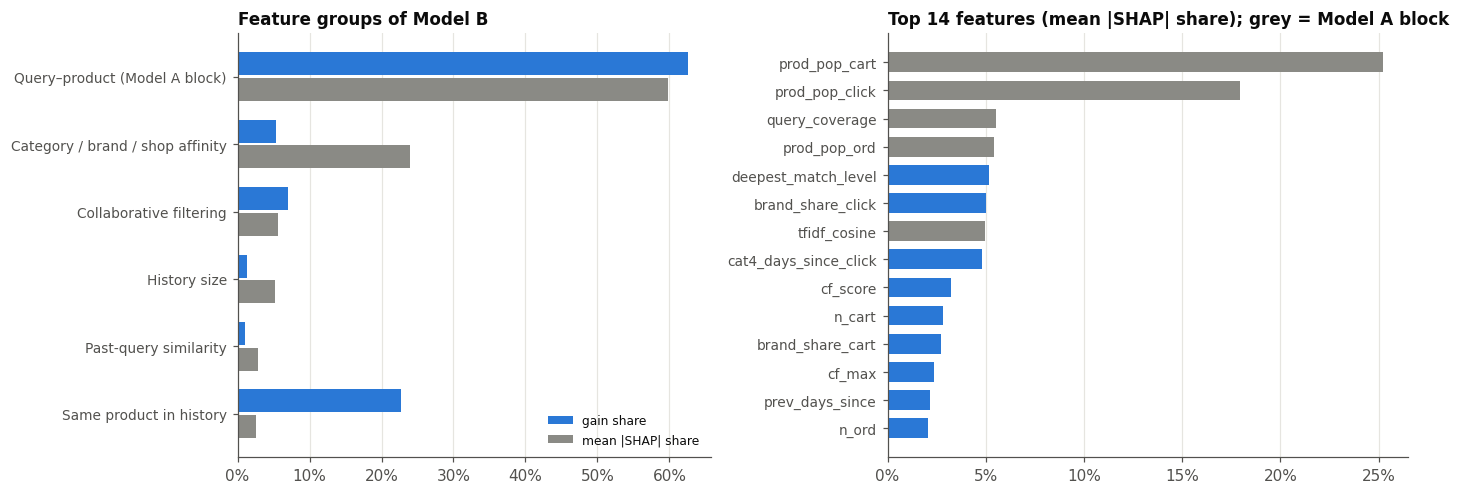

In [ ]:
def group_of(f):
    if f in FEATURES_A: return 'Query–product (Model A block)'
    if f in ('n_ord', 'n_cart', 'n_click'): return 'History size'
    if f.startswith('prev_'): return 'Same product in history'
    if f.startswith(('cat4_', 'brand_', 'shop_', 'deepest_')): return 'Category / brand / shop affinity'
    if f.startswith('pqs_'): return 'Past-query similarity'
    if f.startswith('cf_'): return 'Collaborative filtering'
    return 'Other history'
GROUP_COLS = {}
for f in FEATURES_B: GROUP_COLS.setdefault(group_of(f), []).append(f)
HIST_GROUPS = {g: c for g, c in GROUP_COLS.items() if not g.startswith('Query')}
print({g: len(c) for g, c in GROUP_COLS.items()})

gain = pd.Series(model_B.feature_importance('gain'), index=FEATURES_B)
rng = np.random.default_rng(SEED)
sample = data[FEATURES_B].iloc[np.sort(rng.choice(len(data), size=min(20000, len(data)), replace=False))]
shap_abs = pd.Series(np.abs(model_B.predict(sample, pred_contrib=True)[:, :-1]).mean(axis=0), index=FEATURES_B)
imp = pd.DataFrame({'gain_share': gain / gain.sum(), 'shap_share': shap_abs / shap_abs.sum()})
imp['group'] = [group_of(f) for f in imp.index]
imp_group = imp.groupby('group')[['gain_share', 'shap_share']].sum().sort_values('shap_share', ascending=False)
display(imp_group.style.format('{:.1%}'))
imp.sort_values('shap_share', ascending=False).to_csv(OUT_DIR / 'feature_importance.csv')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.1]})
g = imp_group.iloc[::-1]; y = np.arange(len(g)); h = 0.38
ax[0].barh(y + h / 2, g.gain_share, h * 0.9, color=C['B'], label='gain share'); ax[0].barh(y - h / 2, g.shap_share, h * 0.9, color=C['A'], label='mean |SHAP| share')
ax[0].set_yticks(y); ax[0].set_yticklabels(g.index, fontsize=9); ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax[0].set_title('Feature groups of Model B'); ax[0].legend(frameon=False, fontsize=8, loc='lower right'); clean(ax[0])
t = imp.sort_values('shap_share').tail(14)
ax[1].barh(range(len(t)), t.shap_share, color=[C['A'] if gp.startswith('Query') else C['B'] for gp in t.group], height=0.7)
ax[1].set_yticks(range(len(t))); ax[1].set_yticklabels(t.index, fontsize=9); ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax[1].set_title('Top 14 features (mean |SHAP| share); grey = Model A block'); clean(ax[1])
save_show(fig, '5_importance')

reference: Model B 0.4060, Model A 0.3526


,ndcg_without,delta_vs_B,ci_low,ci_high
group,,,,
All history features,0.3474,-0.0585,-0.0615,-0.0556
Same product in history,0.3660,-0.0400,-0.0422,-0.0378
Collaborative filtering,0.3983,-0.0077,-0.0091,-0.0064
Category / brand / shop affinity,0.4005,-0.0055,-0.0068,-0.0042
History size,0.4054,-0.0005,-0.0014,+0.0002
Past-query similarity,0.4057,-0.0002,-0.0011,+0.0007


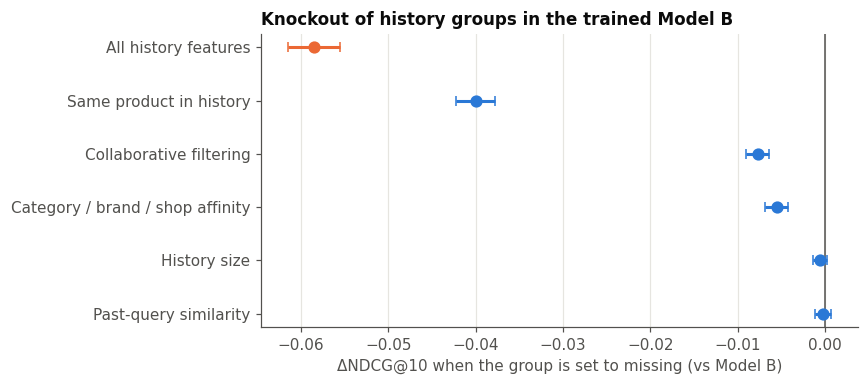

In [ ]:
# 5.2 inference-time knockout: set one history group to missing, re-score with the trained Model B
def knock(cols):
    X = data[FEATURES_B].copy(); X[cols] = np.nan
    return model_B.predict(X)
ko_scores = {g: knock(c) for g, c in HIST_GROUPS.items()}
ko_scores['All history features'] = knock(HISTORY)
rows = []
for g, sc in ko_scores.items():
    pqk = evaluate(sc, per_query=True).set_index('user_id')
    mean, lo, hi, _ = paired_boot((pqk.ndcg10 - pq['Model B'].ndcg10).to_numpy(), 500)
    rows.append(dict(group=g, ndcg_without=pqk.ndcg10.mean(), delta_vs_B=mean, ci_low=lo, ci_high=hi))
knock_tbl = pd.DataFrame(rows).set_index('group').sort_values('delta_vs_B')
print(f"reference: Model B {pq['Model B'].ndcg10.mean():.4f}, Model A {pq['Model A'].ndcg10.mean():.4f}")
display(knock_tbl.style.format('{:+.4f}', subset=['delta_vs_B', 'ci_low', 'ci_high']).format('{:.4f}', subset=['ndcg_without']))
knock_tbl.to_csv(OUT_DIR / 'knockout.csv')

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (g, r) in enumerate(knock_tbl.iterrows()):
    ax.errorbar(r.delta_vs_B, i, xerr=[[r.delta_vs_B - r.ci_low], [r.ci_high - r.delta_vs_B]], fmt='o', color=C['down'] if g.startswith('All') else C['B'], ms=7, capsize=3, lw=2)
ax.axvline(0, color=C['mute'], lw=1); ax.set_yticks(range(len(knock_tbl))); ax.set_yticklabels(knock_tbl.index); ax.invert_yaxis()
ax.set_xlabel('ΔNDCG@10 when the group is set to missing (vs Model B)'); ax.set_title('Knockout of history groups in the trained Model B'); clean(ax)
save_show(fig, '5_knockout')

### 5.3 Retrained ablations
Models are retrained with the shared LightGBM settings on one training subset (one chunk, at most `ABL_MAX_QUERIES` queries), with early stopping on the tie-safe validation NDCG@10. Learning rate is raised to `ABL_LR` to keep the run short. Every variant uses the same subset, so differences between variants are due to the feature set; the first two rows (A and B retrained on the subset) are the references, and the full-data Model A/B above stay the headline result.

Per-query results are cached in `ablation_per_query.parquet`; a rerun after a disconnect resumes where it stopped. Set `RUN_ABLATIONS = False` to skip.

In [ ]:
RUN_ABLATIONS = False
ABL_MAX_QUERIES, ABL_LR, ABL_ROUNDS, ABL_PATIENCE = 30000, 0.1, 600, 30
ABL_TAG = next((t for t in ('train_c0', 'train_dev') if (FEATURE_DIR / f'featA_{t}.parquet').is_file()), None)

ordf = [f for f in HISTORY if f.endswith('_ord')]; cartf = [f for f in HISTORY if f.endswith('_cart')]; clickf = [f for f in HISTORY if f.endswith('_click')]
order_in_B = lambda cols: [f for f in FEATURES_B if f in set(cols)]
variants = {'A: 7 query–product features': FEATURES_A, 'B: all 30 features': FEATURES_B}
for g, c in HIST_GROUPS.items(): variants[f'A + {g} only'] = FEATURES_A + c
for g, c in HIST_GROUPS.items(): variants[f'B − {g}'] = order_in_B(set(FEATURES_B) - set(c))
variants['A + order signals'] = FEATURES_A + ordf
variants['A + order + cart signals'] = FEATURES_A + ordf + cartf
variants['A + order + cart + click signals'] = FEATURES_A + ordf + cartf + clickf

if RUN_ABLATIONS and ABL_TAG is None: print('no training feature files found: skipping ablations'); RUN_ABLATIONS = False
if RUN_ABLATIONS:
    import time
    tr = load_eval(ABL_TAG)
    keep_u = np.sort(np.random.default_rng(SEED).choice(tr.user_id.unique(), size=min(ABL_MAX_QUERIES, tr.user_id.nunique()), replace=False))
    tr = tr[tr.user_id.isin(keep_u)].reset_index(drop=True)
    print(f'ablation training subset: {tr.user_id.nunique():,} queries, {len(tr):,} rows ({ABL_TAG})')
    if SPLIT == 'val': dv, ev_v = data, evaluate
    else:
        dv = load_eval('val'); ev_v = make_evaluator(dv[KEYS], dv.label.to_numpy(), k=K, seed=SEED)
    g_tr = tr.groupby('user_id', sort=False).size().to_numpy(); g_dv = dv.groupby('user_id', sort=False).size().to_numpy()
    P = {k: v for k, v in cfg_A['parameters'].items() if k not in ('n_estimators', 'early_stopping_rounds', 'n_jobs')}
    P['learning_rate'] = ABL_LR

    def fit_variant(feats):
        dtr = lgb.Dataset(tr[feats], tr.label.to_numpy(), group=g_tr, free_raw_data=False)
        dva = lgb.Dataset(dv[feats], dv.label.to_numpy(), group=g_dv, reference=dtr, free_raw_data=False)
        feval = lambda preds, ds: ('ndcg10_tiesafe', ev_v(preds)['ndcg10'], True)
        return lgb.train(P, dtr, num_boost_round=ABL_ROUNDS, valid_sets=[dva], feval=feval,
                         callbacks=[lgb.early_stopping(ABL_PATIENCE, first_metric_only=True, verbose=False)])

    cache = OUT_DIR / 'ablation_per_query.parquet'; meta_f = OUT_DIR / 'ablation_meta.json'
    abl = pd.read_parquet(cache) if cache.is_file() else pd.DataFrame(index=pq['Model A'].index)
    meta = json.loads(meta_f.read_text()) if meta_f.is_file() else {}
    for name, feats in variants.items():
        if name in abl.columns: continue
        t0 = time.time(); bst = fit_variant(feats)
        sc = bst.predict(data[feats], num_iteration=bst.best_iteration)
        abl[name] = evaluate(sc, per_query=True).set_index('user_id').ndcg10.reindex(abl.index)
        meta[name] = dict(best_iteration=int(bst.best_iteration), n_features=len(feats), seconds=round(time.time() - t0))
        abl.to_parquet(cache); meta_f.write_text(json.dumps(meta, indent=1))
        print(f"{name:45s} NDCG@10 {abl[name].mean():.4f}  ({bst.best_iteration} trees, {time.time() - t0:.0f}s)")

    refA, refB = abl['A: 7 query–product features'], abl['B: all 30 features']
    rows = []
    for name in variants:
        r = dict(variant=name, features=meta[name]['n_features'], trees=meta[name]['best_iteration'], ndcg10=abl[name].mean())
        for tag, ref in (('vs_A', refA), ('vs_B', refB)):
            mean, lo, hi, _ = paired_boot((abl[name] - ref).to_numpy(), 500); r.update({f'delta_{tag}': mean, f'lo_{tag}': lo, f'hi_{tag}': hi})
        rows.append(r)
    abl_tbl = pd.DataFrame(rows).set_index('variant')
    display(abl_tbl.style.format('{:.4f}', subset=['ndcg10']).format('{:+.4f}', subset=[c for c in abl_tbl.columns if c.startswith(('delta', 'lo_', 'hi_'))]))
    abl_tbl.to_csv(OUT_DIR / 'ablations.csv')
    print(f"retrained on the subset: A {refA.mean():.4f}, B {refB.mean():.4f}, gain {refB.mean() - refA.mean():+.4f} "
          f"(full-data models: {pq['Model A'].ndcg10.mean():.4f}, {pq['Model B'].ndcg10.mean():.4f}, gain {d_ndcg.delta:+.4f})")

    def forest(ax, names, col, title, xlabel):
        for i, n in enumerate(names):
            r = abl_tbl.loc[n]; d, lo, hi = r[f'delta_{col}'], r[f'lo_{col}'], r[f'hi_{col}']
            ax.errorbar(d, i, xerr=[[d - lo], [hi - d]], fmt='o', color=C['B'], ms=7, capsize=3, lw=2)
        ax.axvline(0, color=C['mute'], lw=1); ax.set_yticks(range(len(names))); ax.set_yticklabels([n.split(' only')[0].split('B − ')[-1] if 'only' in n or 'B −' in n else n for n in names], fontsize=8)
        ax.invert_yaxis(); ax.set_title(title); ax.set_xlabel(xlabel); clean(ax)
    alone = [f'A + {g} only' for g in HIST_GROUPS] + ['B: all 30 features']
    removed = [f'B − {g}' for g in HIST_GROUPS]
    layers = ['A + order signals', 'A + order + cart signals', 'A + order + cart + click signals', 'B: all 30 features']
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    forest(ax[0], alone, 'vs_A', 'Adding one group to A', 'ΔNDCG@10 vs retrained A')
    forest(ax[1], removed, 'vs_B', 'Removing one group from B', 'ΔNDCG@10 vs retrained B')
    forest(ax[2], layers, 'vs_A', 'Signal layers added to A', 'ΔNDCG@10 vs retrained A')
    ax[2].set_yticklabels(['orders', '+ carts', '+ clicks', '+ mixed-signal features (all 30)'], fontsize=8)
    save_show(fig, '5_ablations')
else:
    print('ablations skipped')

ablations skipped


### 5.4 Collaborative filtering coverage
`cf_max` and `cf_score` are missing for candidates whose product has too few fitting users (fewer than 5). The model reads that as "no CF information", so the CF gain can only come from covered candidates. This cell reports coverage, and the CF knockout effect for queries with and without a covered relevant product.

In [ ]:
cov = data.cf_max.notna().to_numpy(); is_pos = data.label.to_numpy() > 0
print(f'CF coverage: {cov.mean():.1%} of candidates, {cov[is_pos].mean():.1%} of relevant candidates, {cov[~is_pos].mean():.1%} of non-relevant candidates')
cf_group = 'Collaborative filtering'
if cf_group in ko_scores:
    cov_pos = pd.Series(cov & is_pos, index=data.user_id.to_numpy()).groupby(level=0).any().reindex(pq['Model B'].index)
    pqk = evaluate(ko_scores[cf_group], per_query=True).set_index('user_id')
    d_cf = (pqk.ndcg10 - pq['Model B'].ndcg10)
    rows = []
    for lab, m in (('a relevant product has CF values', cov_pos.to_numpy()), ('no relevant product covered by CF', ~cov_pos.to_numpy())):
        mean, lo, hi, _ = paired_boot(d_cf.to_numpy()[m], 500)
        rows.append(dict(queries=lab, n=int(m.sum()), delta_when_CF_removed=mean, ci_low=lo, ci_high=hi))
    cf_tbl = pd.DataFrame(rows).set_index('queries'); display(cf_tbl.style.format('{:+.4f}', subset=['delta_when_CF_removed', 'ci_low', 'ci_high'])); cf_tbl.to_csv(OUT_DIR / 'cf_coverage.csv')

CF coverage: 18.3% of candidates, 45.3% of relevant candidates, 17.7% of non-relevant candidates


,n,delta_when_CF_removed,ci_low,ci_high
queries,,,,
a relevant product has CF values,15512,-0.0166,-0.0187,-0.0145
no relevant product covered by CF,10255,+0.0059,+0.0052,+0.0067


## 6. Summary for the report
The cell below assembles the headline numbers from the tables above and writes them in plain language. All tables and figures are saved to `Data/Results/ModelComparison/<split>/`.

In [ ]:
def ci_txt(r): return f'{r.delta:+.4f} [{r.ci_low:+.4f}, {r.ci_high:+.4f}]'
lines = []
n_q = len(Q)
lines.append(f"MAIN RESULT ({SPLIT}, {n_q:,} queries). Adding shopper history changes NDCG@10 from {d_ndcg.model_A:.4f} to {d_ndcg.model_B:.4f}: {ci_txt(d_ndcg)}, "
              f"a relative gain of {d_ndcg.relative_gain_pct:+.1f}%. "
              f"MRR {ci_txt(main.loc['MRR'])}; Hit@10 {ci_txt(main.loc['Hit@10'])}. "
              f"B is better in {share['better']:.1%} of queries and worse in {share['worse']:.1%}. "
              + ('The gain is distinguishable from zero.' if d_ndcg.ci_low > 0 else 'The interval includes zero, so the gain is not reliable.'))
big = strata[strata.n >= MIN_N]
for dim in dims:
    s = big[big.dimension == dim]
    if len(s) < 2: continue
    hi_, lo_ = s.loc[s.delta.idxmax()], s.loc[s.delta.idxmin()]
    lines.append(f"{dim.upper()}: largest gain for '{hi_.group}' ({ci_txt(hi_)}, n={hi_.n:,}); smallest for '{lo_.group}' ({ci_txt(lo_)}, n={lo_.n:,}).")
lines.append(f"DRIVERS (mean |SHAP|): " + ', '.join(f'{g} {v:.0%}' for g, v in imp_group.shap_share.drop(index='Query–product (Model A block)').head(3).items()) + f" (history groups; the Model A block holds {imp_group.shap_share['Query–product (Model A block)']:.0%})" + '.')
kt = knock_tbl.drop(index='All history features', errors='ignore')
if len(kt): lines.append(f"KNOCKOUT: removing '{kt.index[0]}' at inference costs {kt.delta_vs_B.iloc[0]:+.4f} NDCG@10 (largest drop); removing all history features gives {knock_tbl.loc['All history features','ndcg_without']:.4f} vs Model B {pq['Model B'].ndcg10.mean():.4f} and Model A {pq['Model A'].ndcg10.mean():.4f}.")
if RUN_ABLATIONS:
    alone_ = abl_tbl.loc[[f'A + {g} only' for g in HIST_GROUPS]].delta_vs_A; rem_ = abl_tbl.loc[[f'B − {g}' for g in HIST_GROUPS]].delta_vs_B
    lines.append(f"RETRAINED ABLATIONS (subset): best single group added to A: '{alone_.idxmax().replace('A + ', '').replace(' only', '')}' ({alone_.max():+.4f}); "
                 f"removing '{rem_.idxmin().replace('B − ', '')}' hurts B most ({rem_.min():+.4f}).")
print('\n\n'.join(lines))
(OUT_DIR / 'summary.txt').write_text('\n\n'.join(lines))
print('\nSaved to', OUT_DIR)

MAIN RESULT (test, 25,767 queries). Adding shopper history changes NDCG@10 from 0.3526 to 0.4060: +0.0533 [+0.0505, +0.0561], a relative gain of +15.1%. MRR +0.0609 [+0.0573, +0.0643]; Hit@10 +0.0506 [+0.0467, +0.0545]. B is better in 28.6% of queries and worse in 18.8%. The gain is distinguishable from zero.

HISTORY AMOUNT (EVENTS): largest gain for '231–3817' (+0.0622 [+0.0556, +0.0676], n=5,143); smallest for '1–22' (+0.0415 [+0.0363, +0.0471], n=5,272).

TIME SINCE LAST EVENT: largest gain for '≤1 day' (+0.0751 [+0.0712, +0.0789], n=16,381); smallest for '90–365 days' (-0.0028 [-0.0143, +0.0086], n=274).

CLICKS IN THE 7-DAY WINDOW: largest gain for 'has clicks' (+0.0596 [+0.0564, +0.0626], n=21,532); smallest for 'no clicks' (+0.0212 [+0.0160, +0.0265], n=4,235).

CARTS IN HISTORY: largest gain for 'has carts' (+0.0540 [+0.0514, +0.0570], n=24,634); smallest for 'no carts' (+0.0375 [+0.0269, +0.0489], n=1,133).

ORDERS IN HISTORY: largest gain for 'no orders' (+0.0571 [+0.0478, +